In [1]:
import numpy as np
import skimage.io
import skimage.transform
import matplotlib.pyplot as plt
import constants
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
import joblib
import cv2
import seaborn as sn
import pandas as pd
import matplotlib.patches as patches
import time

In [2]:
name = 'RGB00483'
image = cv2.imread(f'./testing/raw/{name}.JPG')

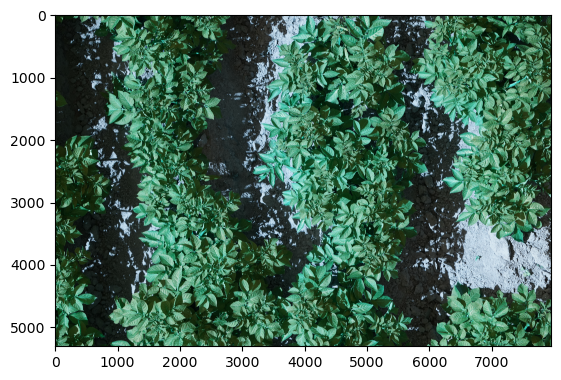

In [3]:
plt.imshow(image)

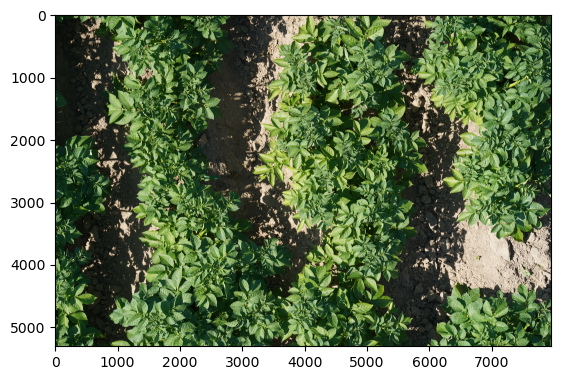

In [4]:
test = skimage.io.imread(f'./testing/raw/{name}.JPG')
plt.imshow(test)

In [5]:
def img_to_512(image):
    # height = len(image)
    # width = len(image[0])
    # size_piece = 512
    labels = []
    pieces = []
    y = 0
    while(y < constants.Y_END - constants.WIDTH_PIECE): #zijkanten worden weggegooid indien te klein
        x = 0
        while(x < constants.X_END - constants.WIDTH_PIECE): #zijkanten worden weggegooid indien te klein
            x_end = x+constants.WIDTH_PIECE if x+constants.WIDTH_PIECE < constants.X_END else constants.X_END
            y_end = y+constants.WIDTH_PIECE if y+constants.WIDTH_PIECE < constants.Y_END else constants.Y_END
            #cut a piece
            img_piece = image[y:y_end,x:x_end]
            pieces.append(img_piece)
            coordinate = [x + constants.WIDTH_PIECE / 2, y + constants.WIDTH_PIECE / 2]
            labels.append(coordinate)
            x += constants.WIDTH_PIECE
        y += constants.WIDTH_PIECE
    
    return labels, pieces

In [6]:
labels, pieces = img_to_512(image)

In [7]:
# plt.imshow(image)
# plt.scatter(*zip(*labels), alpha=0.7, c='darkred', s=15)

In [8]:
def filter_512(data, labels, model):
    filtered_data = []
    filtered_label = []
    aantal = len(data)

    for i in range(aantal):
        img = skimage.transform.resize(data[i], (64,64))
        img = img.reshape((1,-1))
        # print(model.predict(img))
        prediction = model.predict(img)
        if prediction == 1:
            filtered_data.append(data[i])
            filtered_label.append(labels[i])
        print(f'{i}/{aantal}', end='\r')
    print(f'{aantal}/{aantal}')

    return filtered_data, filtered_label

In [9]:
model512 = joblib.load('./trained_models/kmeans')
filtered_data, filtered_label = filter_512(pieces, labels, model512)

150/150


In [10]:
# print(filtered_data)
filtered_data = np.array(filtered_data)
filtered_data = filtered_data / 255
# print(filtered_data)

De afbeelding wordt opgestplits. De coordinaten zijn
```
[0, 1]
[2, 3]
```

In [11]:
def filter_split(data, labels, model, size):
    aantal = len(data)
    filtered_data = []
    filtered_label = []
    result = []

    for i in range(aantal):
        image = data[i]
        M = image.shape[0]//2
        N = image.shape[1]//2
        tiles = [image[y:y+N, x:x+M] for y in range(0,image.shape[1],N) for x in range(0,image.shape[0],M)]
        x_center, y_center = labels[i]
        # print(x_center, y_center)
        for j in range(4):
            img = tf.reshape(tiles[j], [1, size, size, 3])
            prediction = model.predict(img, verbose=0)
            # print(j%2, j//2)
            coordinate = [x_center - size/2 + size*(j%2) , y_center - size/2 + size*(j//2)]
            # print(coordinate)
            # print(prediction)
            if prediction[0] > 0.5:
                filtered_data.append(tiles[j])
                filtered_label.append(coordinate)
                continue
            result.append(prediction[0])
        
        print(f"{i}/{aantal}", end='\r')
    print(f"{aantal}/{aantal}")

    return filtered_data, filtered_label, result

In [12]:
model256 = keras.models.load_model('./trained_models/model256_classweight/')
filtered_data256, filtered_label256, result = filter_split(filtered_data, filtered_label, model256, 256)

145/145


In [13]:
# print(result)
# plt.boxplot(result)

In [14]:
# print(len(filtered_data256))
# x, y = filtered_label256[33]
# print(x, y)

# fig, axes = plt.subplots(nrows=1, ncols=2)
# axes[0].imshow(filtered_data256[33])
# axes[1].imshow(image[int(y)-128:int(y)+128, int(x)-128:int(x)+128])

In [15]:
model128 = keras.models.load_model('./trained_models/model128/')
filtered_data128, filtered_label128, result = filter_split(filtered_data256, filtered_label256, model128, 128)

3/3


In [16]:
# print(len(filtered_data128))
# x, y = filtered_label128[82]
# print(x, y)

# fig, axes = plt.subplots(nrows=1, ncols=2)
# axes[0].imshow(filtered_data256[33])
# axes[1].imshow(image[int(y)-64:int(y)+64, int(x)-64:int(x)+64])

In [17]:
model64 = keras.models.load_model('./trained_models/model64/')
filtered_data64, filtered_label64, result = filter_split(filtered_data128, filtered_label128, model64, 64)

3/3


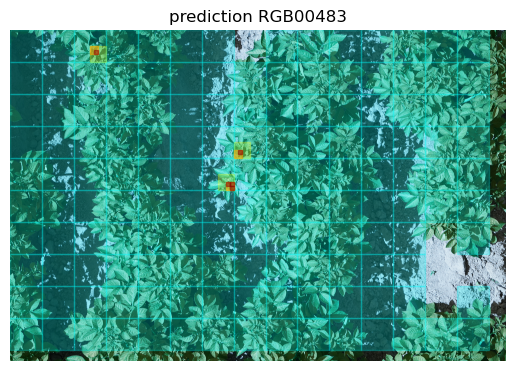

In [18]:
ax = plt.subplot()

ax.imshow(image)
ax.set_title(f'prediction {name}')
ax.axis('off')

size = 512
for x, y in filtered_label:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'aqua', facecolor= 'aqua', alpha=0.25)
    ax.add_patch(rect)
size = 256
for x, y in filtered_label256:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'yellow', facecolor= 'yellow', alpha=0.25)
    ax.add_patch(rect)
size = 128
for x, y in filtered_label128:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'orange', facecolor= 'orange', alpha=0.5)
    ax.add_patch(rect)
size = 64
for x, y in filtered_label64:
    rect = patches.Rectangle([x-size/2, y-size/2], size, size, edgecolor = 'darkred', facecolor= 'darkred', alpha=0.5)
    ax.add_patch(rect)
# plt.savefig(f'./testing/function/{name}.png')

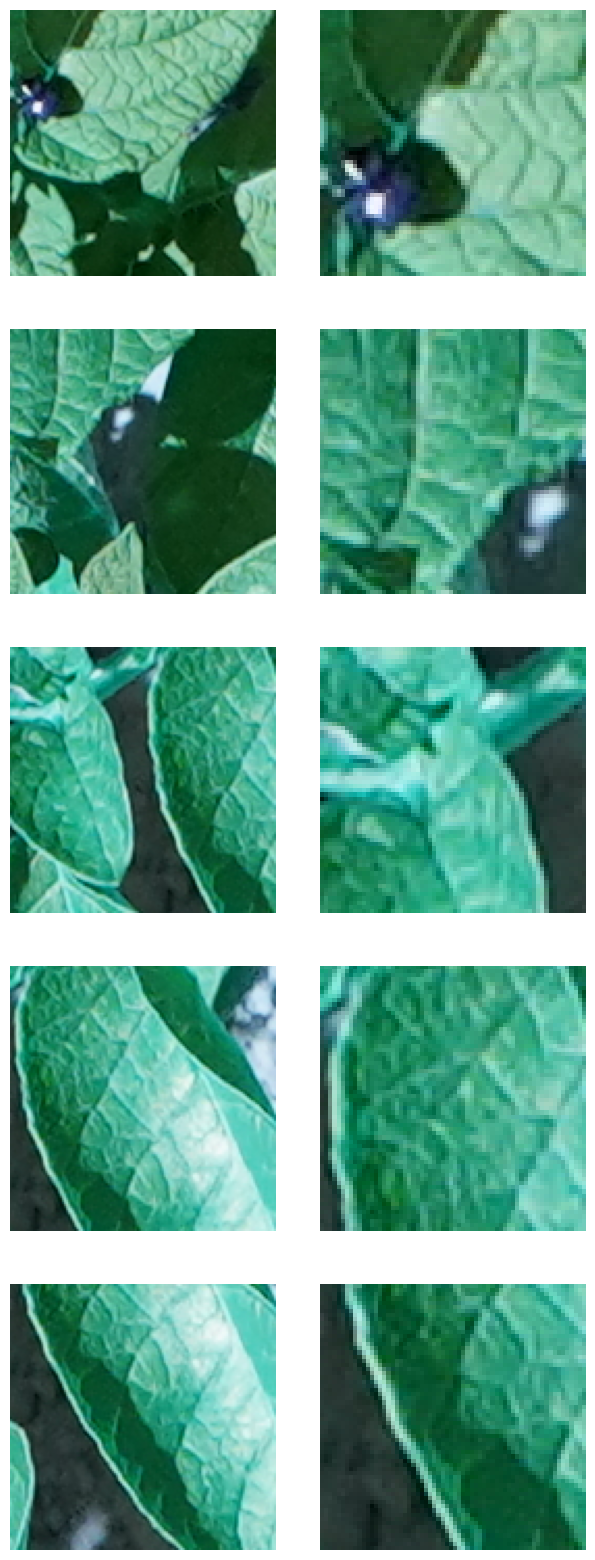

In [19]:
aantal = len(filtered_data64)
# print(aantal)
fig, axes = plt.subplots(nrows=aantal, ncols=2, figsize = (20,20))
plt.subplots_adjust(wspace=-0.75)
for i in range(aantal):
    x, y = filtered_label64[i]
    # print(x, y)

    axes[i][0].imshow(image[int(y)-32:int(y)+96, int(x)-32:int(x)+96])
    axes[i][0].axis('off')
    axes[i][1].imshow(image[int(y)-32:int(y)+32, int(x)-32:int(x)+32])
    axes[i][1].axis('off')

In [20]:
# aantal = len(filtered_data64)
# for i in range(aantal):
#     x, y = filtered_label64[i]
#     skimage.io.imsave('./testing/filtered/{:s}_{:.0f}_{:.0f}.png'.format(name,x,y),image[int(y)-32:int(y)+96, int(x)-32:int(x)+96])

In [21]:
# def test_model(data, predict_label, true_labels, size):
#     try:
#         lines = [line.rstrip() for line in true_labels.readlines()]
#     except:
#         lines = []

#     aantal = len(predict_label)
#     TP = 0
#     TN = 0
#     FP = 0
#     FN = 0

#     for i in range(len(predict_label)):
#         delete = []
#         x, y = predict_label[i]
#         for line in lines:
#             _, x_center, y_center, _, _ = [float(s) for s in line.split("\t")]
#             if (x-size/2 < x_center < x+size/2) and (y-size/2 < y_center < y+size/2):
#                 TP += 1
#                 delete.append(line)
#         if len(delete):
#             for el in delete:
#                 lines.remove(el)

#         FP = aantal - TP if aantal > TP else 0

#     FN = len(lines)
#     TN = len(data)*4 - FN - TP - FP
    
#     array = [[TN, FP],
#             [FN, TP]]

#     return array

In [22]:
# labels = open(f"./data/labels_full_txt/{name}.txt")
# array256 = test_model(filtered_data, filtered_label256, labels, 256)

In [23]:
# labels = open(f"./data/labels_full_txt/{name}.txt")
# array128 = test_model(filtered_data256, filtered_label128, labels, 128)

In [24]:
# labels = open(f"./data/labels_full_txt/{name}.txt")
# array64 = test_model(filtered_data128, filtered_label64, labels, 64)

In [25]:
# f1_256 = (2*array256[1][1])/(2*array256[1][1]+array256[0][1]+array256[1][0])
# f1_128 = (2*array128[1][1])/(2*array128[1][1]+array128[0][1]+array128[1][0])
# f1_64 = (2*array64[1][1])/(2*array64[1][1]+array64[0][1]+array64[1][0])

# fig, ax = plt.subplots(nrows=2, ncols=2)
# fig.suptitle(f'{name}_classweights')
# # ax[0][0].imshow(filtered_data[33])
# df256 = pd.DataFrame(array256, range(2), range(2))
# sn.heatmap(df256, ax=ax[0][0], annot=True, center=array256[0][0], fmt='g', cbar=False)
# ax[0][0].set_title('256')
# df128 = pd.DataFrame(array128, range(2), range(2))
# sn.heatmap(df128, ax=ax[0][1], annot=True, center=array128[0][0], fmt='g', cbar=False)
# ax[0][1].set_title('128')
# df64 = pd.DataFrame(array64, range(2), range(2))
# sn.heatmap(df64, ax=ax[1][0], annot=True, center=array64[0][0], fmt='g', cbar=False)
# ax[1][0].set_title('64')

# ax[1][1].set_visible(False)

# fig.text(0.55,0.3,f'f1-score 256: {round(f1_256,4)}\nf1-score 128: {round(f1_128,4)}\nf1-score 64: {round(f1_64,4)}')

# # plt.savefig(f'./documentation/pipeline_confusion_{name}_classweights.png')